# **Laboratory 3: Supervised Learning**

## Breast Cancer Diagnosis Using Supervised Machine Learning: A Comparative Study of Classification Models

MSc in Computational Biomedical Engineering, UPF, 26-27

Roberto Howe & Pablo Méndez

Buscarle un hueco o sino no ponerlo, con ponerlo en el paper final será suficiente yo creo

**Research question: How accurately can supervised learning models distinguish malignant from benign breast tumours using cell nucleus characteristics?**

## 0. Libraries & imports

We are going to use a public dataset in the `ucimlrepo` module, so it's necesary to install it in order to be able to run the following cells.

In [1]:
# In case needed, this is the line to install the module
#!pip install ucimlrepo 

In [2]:
# Data handling and numerical operations
import numpy as np
import pandas as pd

# Visualisation
import matplotlib.pyplot as plt
import seaborn as sns

# Data splitting, cross-validation and hyperparameter tuning
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate,
    GridSearchCV
)

# Preprocessing
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

# Baseline and classification models
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.decomposition import PCA

# Classification evaluation

from sklearn.metrics import (
    accuracy_score, 
    precision_score, 
    recall_score, 
    f1_score, 
    roc_auc_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)

# Feature interpretation
from sklearn.inspection import permutation_importance

# Dataset
from ucimlrepo import fetch_ucirepo

## 1. Dataset loading and EDA

We will use the Wisconsin Diagnostic Breast Cancer (WDBC) dataset, that contains 569 observations and 30 numerical features extracted from images of breast mass sample. The features describe ten characteristics:

| Variable | Meaning |
| :--- | :--- |
| `radius` | Average distance from the centre to the boundary |
| `texture` | Variation in grayscale intensity |
| `perimeter` | Length of the boundary |
| `area` | Area of the nucleus |
| `smoothness` | Local variation in radius lengths |
| `compactness` | Shape compactness, based on perimeter and area |
| `concavity` | Severity of inward curves along the boundary |
| `concave_points` | Number of inward-curving portions |
| `symmetry` | Symmetry of the nucleus |
| `fractal_dimension` | Complexity of the boundary |

Each characteristic has three summaries, giving a total of 30 features:
- 1: Mean.
- 2: Standard error.
- 3: “Worst” defined as the average of the three largest values.

For example, `radius1`, `radius2` and `radius3` represent these three summaries of radius.


https://archive.ics.uci.edu/ml/machine-learning-databases/breast-cancer-wisconsin/wdbc.names

### 1.1. Dataset loading and inspection

In [3]:
# Download the dataset
breast_cancer = fetch_ucirepo(id=17)

# Extract features and the original labels
X = breast_cancer.data.features.copy()
y_original = breast_cancer.data.targets["Diagnosis"].copy()

# Encode malignant as 1 and benign as 0
y = y_original.map({"M": 1, "B": 0}).astype(int)

# Inspect dimensions, feature names and data types
print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nDataset info:")
X.info()

print("\nNumber of duplicated:")
print(X.duplicated().sum())

print("\nOriginal labels:", sorted(y_original.unique()))
print("Encoded labels:", sorted(y.unique()))
print("Target data type:", y.dtype)

print("\nClass counts (0 = benign, 1 = malignant):")
for label, count in y.value_counts().sort_index().items():
    print(f"{label}: {count} ({count / len(y) * 100:.2f}%)")

X shape: (569, 30)
y shape: (569,)

Dataset info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 30 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   radius1             569 non-null    float64
 1   texture1            569 non-null    float64
 2   perimeter1          569 non-null    float64
 3   area1               569 non-null    float64
 4   smoothness1         569 non-null    float64
 5   compactness1        569 non-null    float64
 6   concavity1          569 non-null    float64
 7   concave_points1     569 non-null    float64
 8   symmetry1           569 non-null    float64
 9   fractal_dimension1  569 non-null    float64
 10  radius2             569 non-null    float64
 11  texture2            569 non-null    float64
 12  perimeter2          569 non-null    float64
 13  area2               569 non-null    float64
 14  smoothness2         569 non-null    float64
 15  compact

As we can see in the previous cell, the dataset contains 569 observations and 30 numerical features, with no missing values or duplicate rows. The target variable is encoded as 0 for "benign" and 1 for "malignant" for easier implementations, with 357 (~63%) bening and 212 (~37%) malignant cases observations.

In [4]:
X.describe().T

,count,mean,std,min,25%,50%,75%,max
radius1,569.0,14.127292,3.524049,6.981000,11.700000,13.370000,15.780000,28.11000
texture1,569.0,19.289649,4.301036,9.710000,16.170000,18.840000,21.800000,39.28000
perimeter1,569.0,91.969033,24.298981,43.790000,75.170000,86.240000,104.100000,188.50000
area1,569.0,654.889104,351.914129,143.500000,420.300000,551.100000,782.700000,2501.00000
smoothness1,569.0,0.096360,0.014064,0.052630,0.086370,0.095870,0.105300,0.16340
compactness1,569.0,0.104341,0.052813,0.019380,0.064920,0.092630,0.130400,0.34540
concavity1,569.0,0.088799,0.079720,0.000000,0.029560,0.061540,0.130700,0.42680
concave_points1,569.0,0.048919,0.038803,0.000000,0.020310,0.033500,0.074000,0.20120
symmetry1,569.0,0.181162,0.027414,0.106000,0.161900,0.179200,0.195700,0.30400
fractal_dimension1,569.0,0.062798,0.007060,0.049960,0.057700,0.061540,0.066120,0.09744


The numerical features have different scales, so a future standarization may be needed before training.

### 1.2. Exploratory data analysis (EDA)

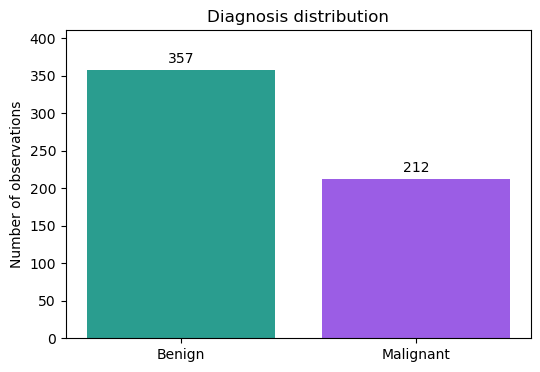

In [5]:
# Plot of the target variable

class_names = ["Benign", "Malignant"]
class_colors = ["#2A9D8F", "#9B5DE5"]

class_counts = y.value_counts().sort_index()

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(class_names, class_counts, color=class_colors)

ax.bar_label(bars, padding=3)
ax.set_ylim(0, class_counts.max() * 1.15)
ax.set_title("Diagnosis distribution")
ax.set_ylabel("Number of observations")

plt.show()

The target classes are slightly imbalanced (62.7% - 37.3%). Since the imbalance is moderate, we will proceed without class balancement.

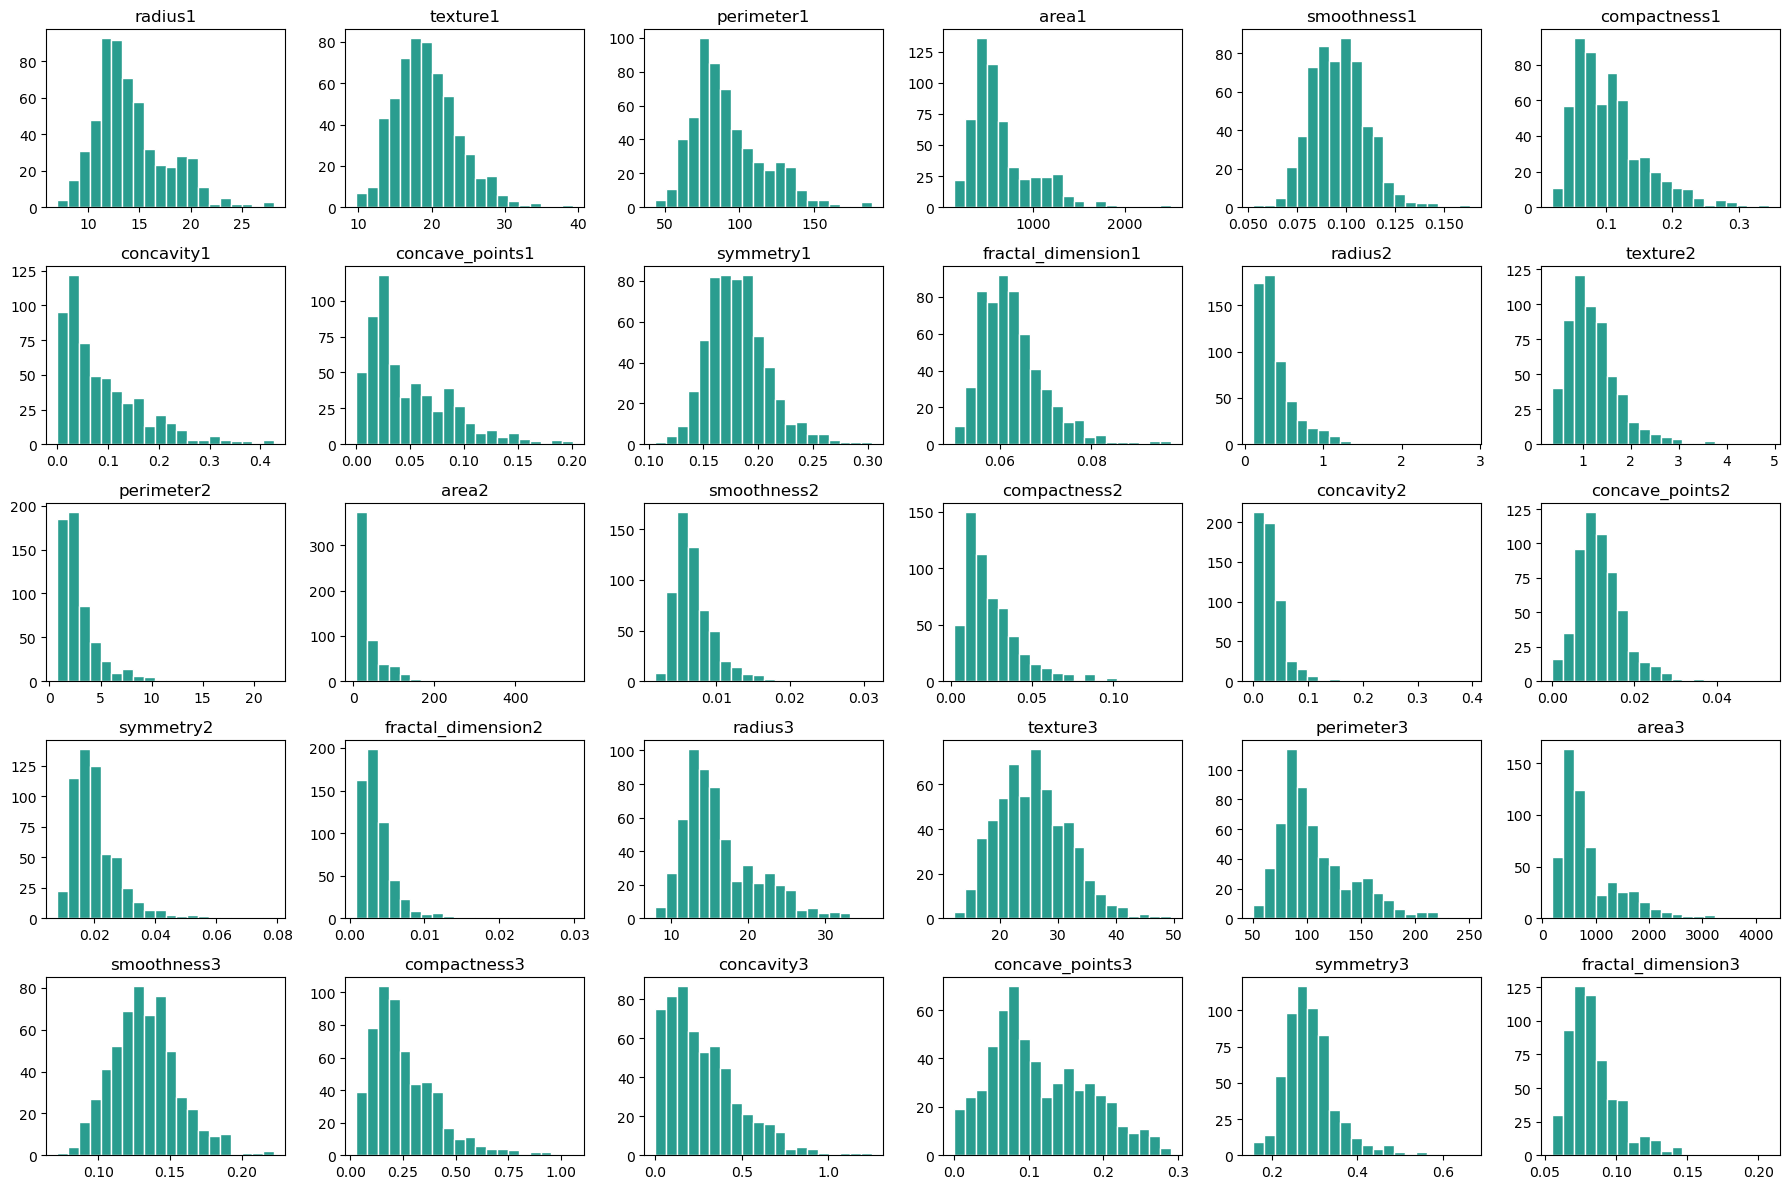

In [6]:
fig, axes = plt.subplots(5, 6, figsize=(18, 12))

for ax, feature in zip(axes.flatten(), X.columns):
    ax.hist(X[feature], bins=20, color="#2A9D8F", edgecolor="white")
    ax.set_title(feature)

plt.tight_layout()
plt.show()

As we can observe in the histograms, many features are right-skewed, with most observations concentrated at lower values. This is specially noticeable in features like `area2`, `concavity2` and `fractal_dimension2`. Other features such as `texture1` and `smoothness1` have more symmetric distributions.

Compare the same measurements across classes using boxplots:

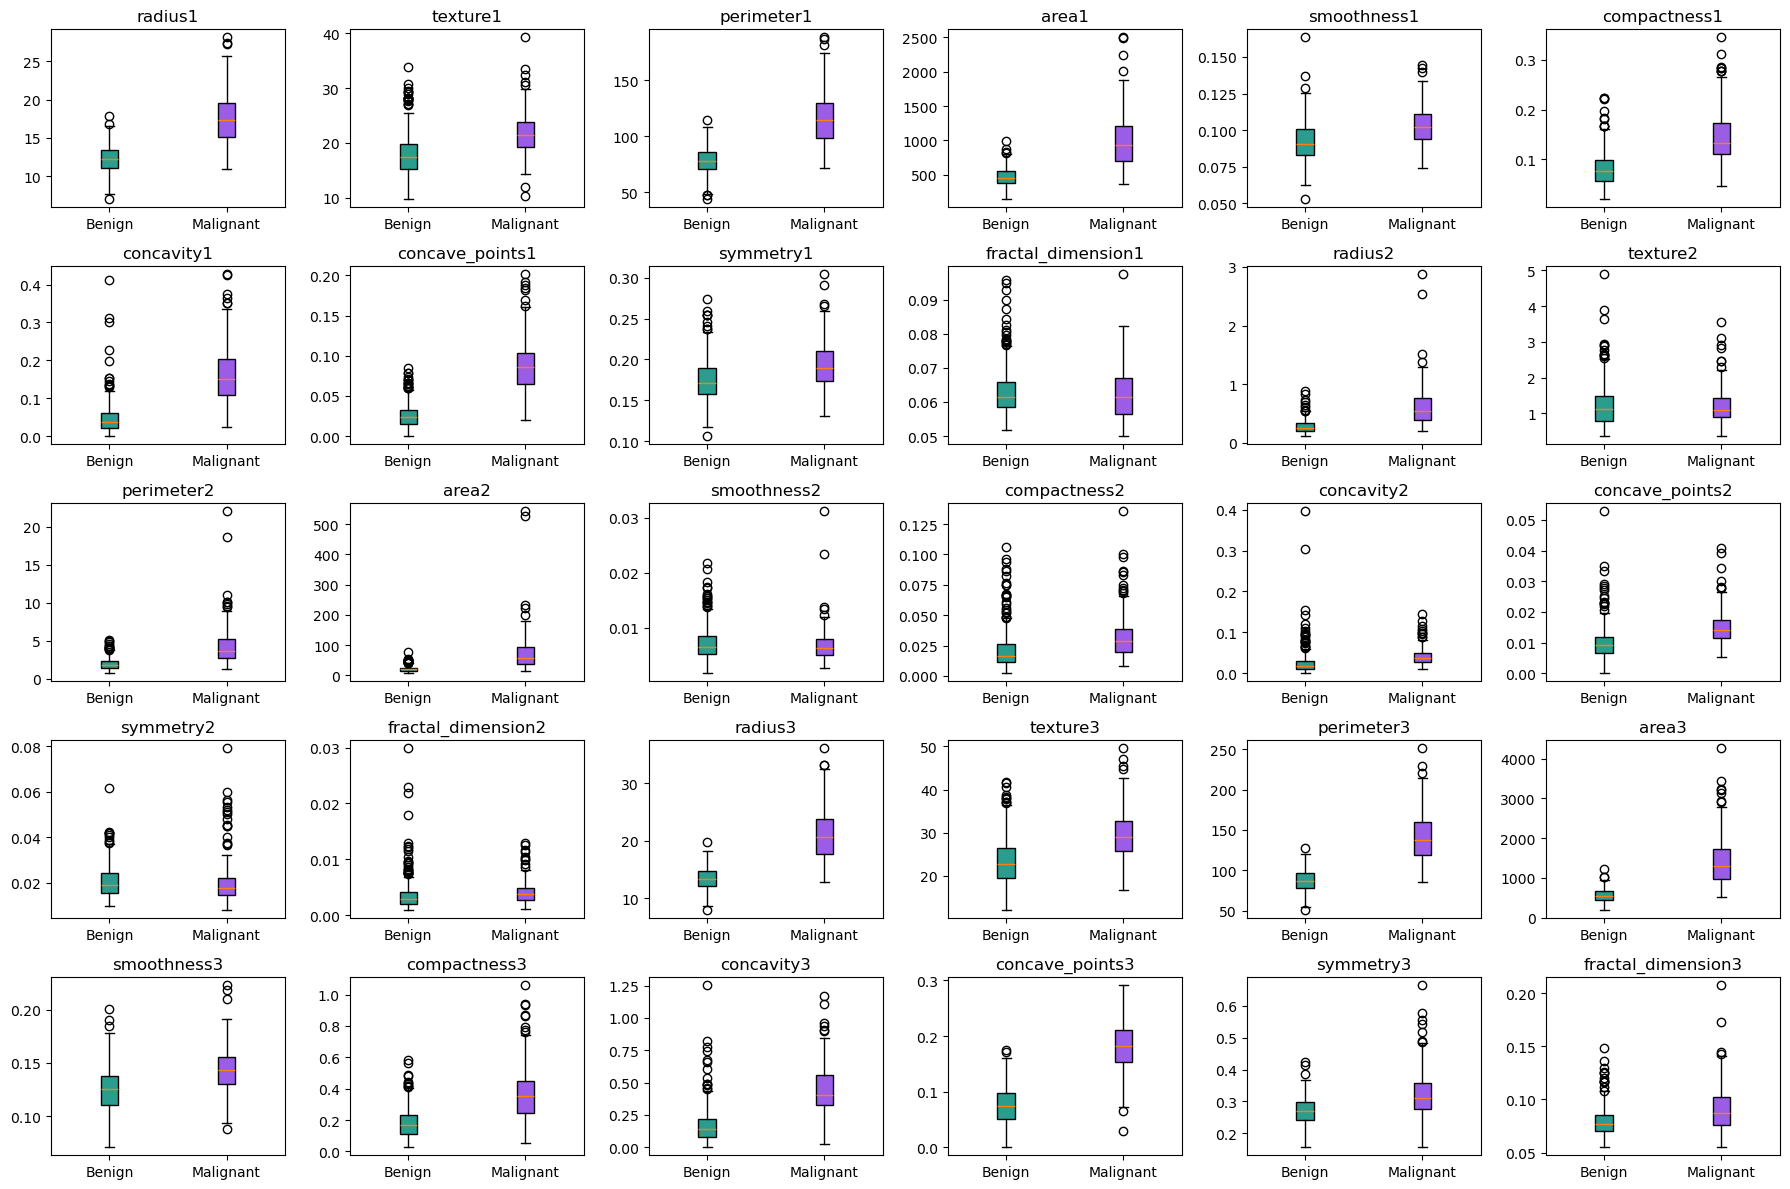

In [7]:
fig, axes = plt.subplots(5, 6, figsize=(18, 12))

for ax, feature in zip(axes.flatten(), X.columns):
    boxes = ax.boxplot(
        [X.loc[y == 0, feature], X.loc[y == 1, feature]],
        patch_artist=True
    )

    for box, color in zip(boxes["boxes"], class_colors):
        box.set_facecolor(color)

    ax.set_xticklabels(class_names)
    ax.set_title(feature)

plt.tight_layout()
plt.show()

There are some features that seem to differenciate the target class better than others. For example, malignant cases have higher radius, perimeter, area, concavity and concave-point values. Other features such as `texture2`, `smoothness2` and `symmetry2` show more overlaping between classes. This plot suggest that some features may help distinguish benign from malignant cases better than others.

Create the correlation heatmap using all predictors, excluding the diagnosis:

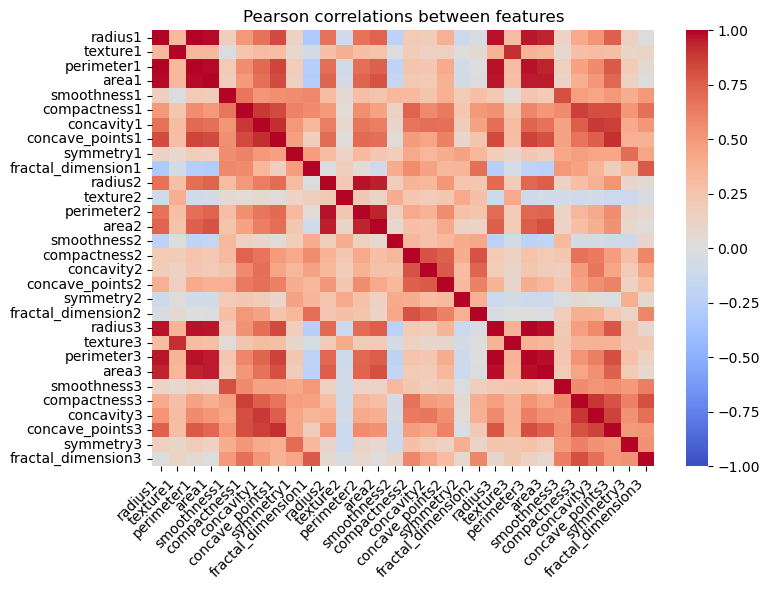

In [8]:
correlation_matrix = X.corr()

plt.figure(figsize=(8, 6))
sns.heatmap(correlation_matrix, cmap="coolwarm", vmin=-1, vmax=1)
plt.xticks(rotation=45, ha="right")
plt.title("Pearson correlations between features")
plt.tight_layout()
plt.show()

In [9]:
for i, feature1 in enumerate(X.columns):
    for feature2 in X.columns[i + 1:]:
        r = correlation_matrix.loc[feature1, feature2]

        if abs(r) >= 0.90:
            print(f"{feature1} - {feature2}: {r:.3f}")

radius1 - perimeter1: 0.998
radius1 - area1: 0.987
radius1 - radius3: 0.970
radius1 - perimeter3: 0.965
radius1 - area3: 0.941
texture1 - texture3: 0.912
perimeter1 - area1: 0.987
perimeter1 - radius3: 0.969
perimeter1 - perimeter3: 0.970
perimeter1 - area3: 0.942
area1 - radius3: 0.963
area1 - perimeter3: 0.959
area1 - area3: 0.959
concavity1 - concave_points1: 0.921
concave_points1 - concave_points3: 0.910
radius2 - perimeter2: 0.973
radius2 - area2: 0.952
perimeter2 - area2: 0.938
radius3 - perimeter3: 0.994
radius3 - area3: 0.984
perimeter3 - area3: 0.978


We can see that several features are strongly correlated, especially radius, perimeter and area.

## 2. Train/test split

We are going to make a 80/20 stratified split to keep similar class proportion in both sets. The validation set is not created because we'll use Cross Validation to train the models

In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

for name, labels in [("Training", y_train), ("Test", y_test)]:
    print(f"\n{name} set: {len(labels)} observations")
    for label, count in labels.value_counts().sort_index().items():
        print(f"Class {label}: {count} ({count / len(labels):.2%})")


Training set: 455 observations
Class 0: 285 (62.64%)
Class 1: 170 (37.36%)

Test set: 114 observations
Class 0: 72 (63.16%)
Class 1: 42 (36.84%)


The training set contains 455 observations and the test set contains 114. Both maintain approximately 63% benign and 37% malignant cases.

## 3. Preprocessing Pipeline

As we saw in the EDA, our features have different scales. We will use `StandardScaler` from `sklearn` to standardize them. Since there are no missing values, no imputation is needed.

We will compare five supervised learning models: **Decission Tree**, **Random Forest**, **Logistic Regression**, **K-Nearest Neighbours (KNN)** and **Support Vectors Machines (SVM)**, using the `DecisionTreeClassifier`, `RandomForestClassifier`, `LogisticRegression`. `KNeighborsClassifier` and `SVC` classes from `sklearn`.

In [11]:
dt_pipeline = Pipeline([
    ("classifier", DecisionTreeClassifier(random_state=42))
])

rf_pipeline = Pipeline([
    ("classifier", RandomForestClassifier(random_state=42))
])

lr_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=2000))
])

knn_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", KNeighborsClassifier())
])

svm_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", SVC())
])

## 4. Baseline model

We use a baseline model that always predict the most frequent class: benign. This provides a reference for evaluating our future models.

In [12]:
baseline = DummyClassifier(strategy="most_frequent")

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}

baseline_results = cross_validate(
    baseline,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring
)

for metric in scoring:
    scores = baseline_results[f"test_{metric}"]
    print(f"{metric}: {scores.mean():.3f}")

accuracy: 0.626
precision: 0.000
recall: 0.000
f1: 0.000
roc_auc: 0.500


c:\ProgramData\miniconda3\envs\py311ml\Lib\site-packages\sklearn\metrics\_classification.py:1509: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\ProgramData\miniconda3\envs\py311ml\Lib\site-packages\sklearn\metrics\_classification.py:1509: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\ProgramData\miniconda3\envs\py311ml\Lib\site-packages\sklearn\metrics\_classification.py:1509: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\ProgramData\minicon

The baseline achieves approximately 62.6% accuracy by predicting every case as benign, looking like it may be a quite useful model if we only focus on that benchmark. However, we can see that both precision and recall are 0.0, making the model useless for real prediction or classification as it's failing to detect any malignant case.

## 5. Classification models

### 5.1. Initial models

We are going to train the five models using their default hyperparameters and 5 fold cross-validation.

In [13]:
models = {
    "Decision Tree": dt_pipeline,
    "Random Forest": rf_pipeline,
    "Logistic Regression": lr_pipeline,
    "KNN": knn_pipeline,
    "SVM": svm_pipeline
}

model_results = {}
summary = {}

for name, model in models.items():
    results = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring
    )
    model_results[name] = results

    summary[name] = {}
    for metric in scoring:
        scores = results[f"test_{metric}"]
        summary[name][metric] = (
            f"{scores.mean():.3f} ± {scores.std(ddof=1):.3f}"
        )

display(pd.DataFrame(summary).T)

,accuracy,precision,recall,f1,roc_auc
Decision Tree,0.923 ± 0.036,0.900 ± 0.045,0.894 ± 0.068,0.896 ± 0.050,0.917 ± 0.042
Random Forest,0.965 ± 0.016,0.964 ± 0.012,0.941 ± 0.047,0.952 ± 0.023,0.989 ± 0.008
Logistic Regression,0.974 ± 0.017,0.977 ± 0.031,0.953 ± 0.045,0.964 ± 0.023,0.996 ± 0.005
KNN,0.965 ± 0.021,0.988 ± 0.028,0.918 ± 0.038,0.951 ± 0.029,0.987 ± 0.015
SVM,0.971 ± 0.006,0.977 ± 0.024,0.947 ± 0.038,0.961 ± 0.009,0.995 ± 0.006


All five models outperform the baseline. Logistic regression achieves the highest mean accuracy (0.974), recall (0.953), f1 (0.964) and ROC-AUC (0.996), followed by SVM. KNN has the highest precision but lower recall than logistic regression, SVM and random forest, meaning it misses mroe malignant cases. Apart from the decision tree, the models perform similarly, with relatively small differences in their scores.

### 5.2. Hyperparameters optimization

Now we will use `GridSearchCV` to test different hyperparameter settings for each model. We keep the same five-fold cross-validation and select the settings with the highest mean ROC-AUC value in the validation split.

First, we need to define the settings to test:

In [14]:
param_grids = {
    "Decision Tree": {
        "classifier__max_depth": [3, 5, None],
        "classifier__min_samples_leaf": [1, 3, 5]
    },
    "Random Forest": {
        "classifier__max_depth": [5, None],
        "classifier__min_samples_leaf": [1, 3, 5]
    },
    "Logistic Regression": {
        "classifier__C": [0.1, 1, 10]
    },
    "KNN": {
        "classifier__n_neighbors": [3, 5, 9, 15],
        "classifier__weights": ["uniform", "distance"]
    },
    "SVM": {
        "classifier__C": [0.1, 1, 10],
        "classifier__gamma": ["scale", 0.01, 0.1]
    }
}

Then run the searches and display the results:

In [15]:
grid_searches = {}
tuned_summary = {}

for name, model in models.items():
    search = GridSearchCV(
        model,
        param_grids[name],
        cv=cv,
        scoring=scoring,
        refit="roc_auc",
        n_jobs=-1
    )
    search.fit(X_train, y_train)
    grid_searches[name] = search

    best = search.best_index_
    tuned_summary[name] = {}

    for metric in scoring:
        scores = np.array([
            search.cv_results_[f"split{i}_test_{metric}"][best]
            for i in range(cv.n_splits)
        ])
        tuned_summary[name][metric] = (
            f"{scores.mean():.3f} ± {scores.std(ddof=1):.3f}"
        )

display(pd.DataFrame(tuned_summary).T)

print("Best hyperparameters for each model:")
for name, search in grid_searches.items():
    print(f"{name}: {search.best_params_}")

,accuracy,precision,recall,f1,roc_auc
Decision Tree,0.925 ± 0.034,0.915 ± 0.048,0.882 ± 0.059,0.898 ± 0.047,0.955 ± 0.030
Random Forest,0.965 ± 0.016,0.964 ± 0.012,0.941 ± 0.047,0.952 ± 0.023,0.989 ± 0.008
Logistic Regression,0.974 ± 0.017,0.977 ± 0.031,0.953 ± 0.045,0.964 ± 0.023,0.996 ± 0.005
KNN,0.960 ± 0.020,0.988 ± 0.017,0.906 ± 0.057,0.944 ± 0.030,0.989 ± 0.011
SVM,0.976 ± 0.012,0.983 ± 0.025,0.953 ± 0.045,0.967 ± 0.018,0.995 ± 0.006


Best hyperparameters for each model:
Decision Tree: {'classifier__max_depth': 5, 'classifier__min_samples_leaf': 5}
Random Forest: {'classifier__max_depth': None, 'classifier__min_samples_leaf': 1}
Logistic Regression: {'classifier__C': 1}
KNN: {'classifier__n_neighbors': 15, 'classifier__weights': 'distance'}
SVM: {'classifier__C': 10, 'classifier__gamma': 0.01}


Hyperparameters tuning produces modest improvements overall. The decission tree's ROC-AUC increases from 0.917 to 0.955, although its recall decreases slightly. SVM improves its overall performance, achieving the highest accuracy (0.976), while logistic regression and random forest maintain their original settings and scores.

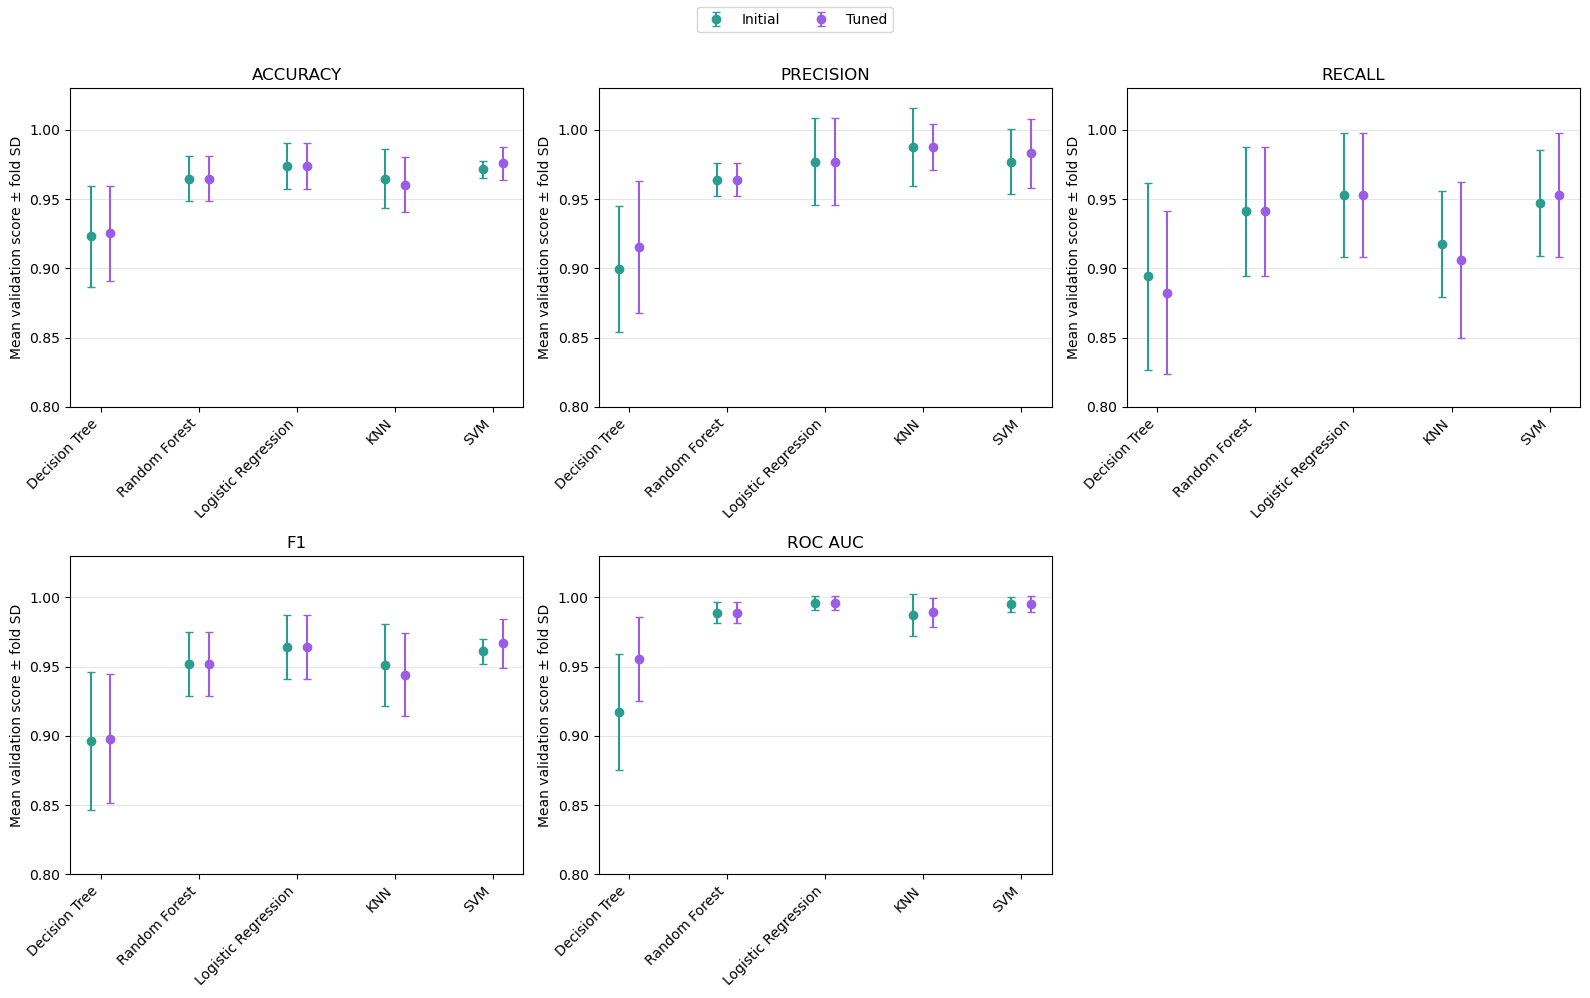

In [16]:
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
positions = np.arange(len(models))

for ax, metric in zip(axes.flat, scoring):
    for offset, tuned, label, color in [
        (-0.1, False, "Initial", "#2A9D8F"),
        (0.1, True, "Tuned", "#9B5DE5")
    ]:
        means, stds = [], []

        for name in models:
            if tuned:
                search = grid_searches[name]
                scores = np.array([
                    search.cv_results_[f"split{i}_test_{metric}"][
                        search.best_index_
                    ]
                    for i in range(cv.n_splits)
                ])
            else:
                scores = model_results[name][f"test_{metric}"]

            means.append(scores.mean())
            stds.append(scores.std(ddof=1))

        ax.errorbar(
            positions + offset, means, yerr=stds,
            fmt="o", capsize=3, label=label, color=color
        )

    ax.set_xticks(positions)
    ax.set_xticklabels(models.keys(), rotation=45, ha="right")
    ax.set_title(metric.replace("_", " ").upper())
    ax.set_ylabel("Mean validation score ± fold SD")
    ax.set_ylim(0.80, 1.03)
    ax.grid(axis="y", alpha=0.3)

fig.delaxes(axes.flat[-1])
handles, labels = axes.flat[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=2)

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

These plots shows a comparision on the different metrics before and after hyperparameters tuning, each dot representing the mean score and the error bars show ± one standard deviation, indicating how much performance varies between folds. 

We can see that tuning does not improve every metric. For example, the decision tree and KNN gain precision and ROC-AUC but loose recall.

## 6. Model interpretation

We are going to focus on logistic regression because it achieved the highest overall performance and provides interpretable coefficients. Positive coefficients favour a malignant prediction, while negative coefficients favour a benign prediction.

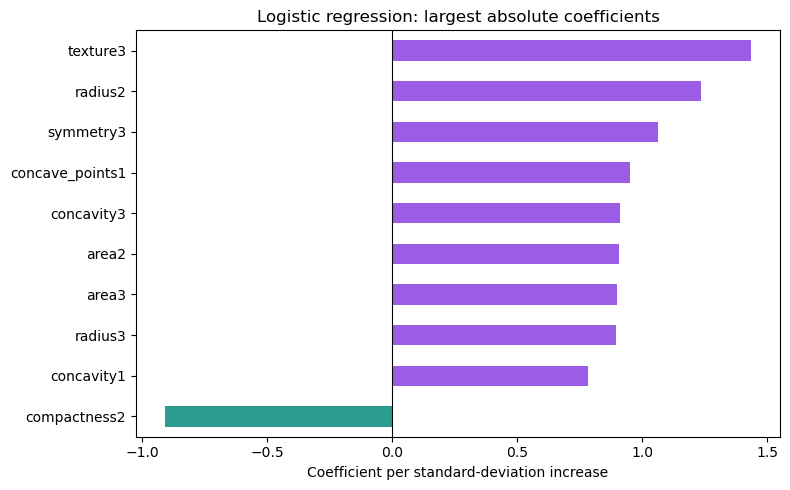

In [17]:
lr_model = grid_searches["Logistic Regression"].best_estimator_

coefficients = pd.Series(
    lr_model.named_steps["classifier"].coef_[0],
    index=X_train.columns
)

top_features = coefficients.abs().nlargest(10).index
top_coefficients = coefficients[top_features].sort_values()

top_coefficients.plot.barh(
    figsize=(8, 5),
    color=["#9B5DE5" if value > 0 else "#2A9D8F"
           for value in top_coefficients]
)

plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("Coefficient per standard-deviation increase")
plt.title("Logistic regression: largest absolute coefficients")
plt.tight_layout()
plt.show()

Texture3, radius2 and symmetry3 have the largest positive coefficients, meaning higher values push the model towards a malignant prediction when the other features are held constant. Compactness2 has a negative coefficient, pushing predictions towards benign. However, these coefficients should be interpreted cauitiously because several features are strongly correlated.

## 7. Feature Selection

As we already saw on the EDA, there are some correlated features in the dataset. So, in this section we are going to focus on the logistic regression model and test if it can achieve similar performance using fewer features.

In order to implement this, we are using `SelectKBest` function that ranks features individually using the ANOVA F-score, which measure differences between the two diagnossis classes for each feature. Then, we will compare subsets of 5, 10 and 15 features and tune the regularization parameter `C`.

In [18]:
fs_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("selector", SelectKBest(score_func=f_classif)),
    ("classifier", LogisticRegression(max_iter=2000))
])

fs_search = GridSearchCV(
    fs_pipeline,
    param_grid={
        "selector__k": [5, 10, 15],
        "classifier__C": [0.1, 1, 10]
    },
    cv=cv,
    scoring=scoring,
    refit="roc_auc",
    n_jobs=-1
)

fs_search.fit(X_train, y_train)

print("Best parameters:", fs_search.best_params_)

Best parameters: {'classifier__C': 10, 'selector__k': 15}


In [19]:
results = pd.DataFrame(fs_search.cv_results_)

fs_table = results[
    ["param_selector__k", "param_classifier__C"]
].copy()

fs_table.columns = ["Features", "C"]

for metric in scoring:
    scores = np.array([
        results[f"split{i}_test_{metric}"]
        for i in range(cv.n_splits)
    ])

    fs_table[metric] = [
        f"{mean:.3f} ± {std:.3f}"
        for mean, std in zip(
            scores.mean(axis=0),
            scores.std(axis=0, ddof=1)
        )
    ]

fs_table = fs_table.loc[
    results["mean_test_roc_auc"].sort_values(ascending=False).index
]

display(fs_table.reset_index(drop=True))

,Features,C,accuracy,precision,recall,f1,roc_auc
0,15,10,0.945 ± 0.032,0.935 ± 0.049,0.918 ± 0.044,0.926 ± 0.043,0.989 ± 0.009
1,15,1,0.943 ± 0.036,0.944 ± 0.046,0.900 ± 0.061,0.921 ± 0.050,0.988 ± 0.008
2,10,10,0.960 ± 0.030,0.964 ± 0.049,0.929 ± 0.034,0.946 ± 0.040,0.986 ± 0.014
3,5,10,0.949 ± 0.020,0.946 ± 0.039,0.918 ± 0.025,0.932 ± 0.027,0.986 ± 0.013
4,10,1,0.954 ± 0.036,0.958 ± 0.057,0.918 ± 0.053,0.937 ± 0.049,0.985 ± 0.013
5,5,1,0.943 ± 0.031,0.940 ± 0.047,0.906 ± 0.067,0.922 ± 0.044,0.985 ± 0.013
6,5,0.1,0.938 ± 0.035,0.951 ± 0.055,0.882 ± 0.072,0.914 ± 0.050,0.985 ± 0.012
7,15,0.1,0.932 ± 0.031,0.944 ± 0.047,0.871 ± 0.061,0.905 ± 0.044,0.985 ± 0.011
8,10,0.1,0.941 ± 0.024,0.957 ± 0.034,0.882 ± 0.062,0.917 ± 0.035,0.984 ± 0.012


In [20]:
selector = fs_search.best_estimator_.named_steps["selector"]
selected_features = X_train.columns[selector.get_support()]

print("Selected features:", selected_features.tolist())

Selected features: ['radius1', 'perimeter1', 'area1', 'compactness1', 'concavity1', 'concave_points1', 'radius2', 'perimeter2', 'area2', 'radius3', 'perimeter3', 'area3', 'compactness3', 'concavity3', 'concave_points3']


Using 15 features and C = 10 halves the number of inputs while retaining a mean validation ROC-AUC of 0.989, compared with 0.996 using all 30 features. However, malignant recall falls from 0.953 to 0.918. The reduced model is simpler, but this loss in recall favours keeping all features.

## 8. PCA

We now use PCA to combine the standardized features into a smaller set of uncorrelated components. We will compare as in the feature selection, sets of 5, 10 and 15 components while tuning C. In this case, the components that PCA retrieves are harder to interpret, that is something important to take into account.

In [21]:
pca_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("pca", PCA()),
    ("classifier", LogisticRegression(max_iter=2000))
])

pca_search = GridSearchCV(
    pca_pipeline,
    param_grid={
        "pca__n_components": [5, 10, 15],
        "classifier__C": [0.1, 1, 10]
    },
    cv=cv,
    scoring=scoring,
    refit="roc_auc",
    n_jobs=-1
)

pca_search.fit(X_train, y_train)

print("Best parameters:", pca_search.best_params_)

Best parameters: {'classifier__C': 1, 'pca__n_components': 15}


In [22]:
results = pd.DataFrame(pca_search.cv_results_)

pca_table = results[
    ["param_pca__n_components", "param_classifier__C"]
].copy()

pca_table.columns = ["Components", "C"]

for metric in scoring:
    scores = np.array([
        results[f"split{i}_test_{metric}"]
        for i in range(cv.n_splits)
    ])

    pca_table[metric] = [
        f"{mean:.3f} ± {std:.3f}"
        for mean, std in zip(
            scores.mean(axis=0),
            scores.std(axis=0, ddof=1)
        )
    ]

pca_table = pca_table.loc[
    results["mean_test_roc_auc"].sort_values(ascending=False).index
]

display(pca_table.reset_index(drop=True))

,Components,C,accuracy,precision,recall,f1,roc_auc
0,15,1,0.974 ± 0.017,0.971 ± 0.029,0.959 ± 0.034,0.964 ± 0.023,0.995 ± 0.006
1,15,0.1,0.974 ± 0.013,0.989 ± 0.026,0.941 ± 0.036,0.964 ± 0.018,0.995 ± 0.006
2,5,1,0.969 ± 0.016,0.970 ± 0.020,0.947 ± 0.038,0.958 ± 0.023,0.995 ± 0.005
3,10,1,0.976 ± 0.020,0.982 ± 0.027,0.953 ± 0.034,0.967 ± 0.027,0.994 ± 0.006
4,10,0.1,0.969 ± 0.014,0.989 ± 0.026,0.929 ± 0.045,0.957 ± 0.021,0.994 ± 0.007
5,10,10,0.974 ± 0.013,0.977 ± 0.024,0.953 ± 0.034,0.964 ± 0.017,0.994 ± 0.005
6,5,10,0.967 ± 0.017,0.964 ± 0.024,0.947 ± 0.038,0.955 ± 0.024,0.994 ± 0.005
7,5,0.1,0.969 ± 0.005,0.989 ± 0.026,0.929 ± 0.026,0.958 ± 0.007,0.994 ± 0.007
8,15,10,0.963 ± 0.013,0.954 ± 0.032,0.947 ± 0.032,0.950 ± 0.017,0.992 ± 0.006


In [23]:
pca = pca_search.best_estimator_.named_steps["pca"]

print(f"Explained variance: {pca.explained_variance_ratio_.sum():.1%}")

Explained variance: 98.7%


The selected PCA configuration uses 15 components and C = 1, retaining 98.7% of the variance in the standardized features. It achieves similar validation performance to the original logistic regression, with ROC-AUC decreasing slightly from 0.996 to 0.995 and recall increasing from 0.953 to 0.959. PCA therefore reduces the classifier’s input dimensions while preserving performance, although the components are harder to interpret and still require all 30 original measurements.

## 9. Final model evaluation

Finally, we will compare the five tuned classifiers with logistic regression using feature selection and PCA. We select the final model by mean cross-validation ROC-AUC and then we will evaluate it on the test set.

In [24]:
candidates = {
    **grid_searches,
    "LR + feature selection": fs_search,
    "LR + PCA": pca_search
}

comparison = {}

for name, search in candidates.items():
    best = search.best_index_
    comparison[name] = {
        metric: search.cv_results_[f"mean_test_{metric}"][best]
        for metric in scoring
    }

final_comparison = pd.DataFrame(comparison).T.sort_values("roc_auc", ascending=False)

display(final_comparison.round(4))

best_name = final_comparison.index[0]
final_model = candidates[best_name].best_estimator_

print("Selected model:", best_name)

,accuracy,precision,recall,f1,roc_auc
Logistic Regression,0.9736,0.9771,0.9529,0.9640,0.9958
SVM,0.9758,0.9830,0.9529,0.9669,0.9954
LR + PCA,0.9736,0.9709,0.9588,0.9644,0.9949
LR + feature selection,0.9451,0.9347,0.9176,0.9259,0.9895
KNN,0.9604,0.9877,0.9059,0.9441,0.9891
Random Forest,0.9648,0.9641,0.9412,0.9519,0.9889
Decision Tree,0.9253,0.9153,0.8824,0.8979,0.9554


Selected model: Logistic Regression


In [25]:
y_pred = final_model.predict(X_test)

if hasattr(final_model, "decision_function"):
    y_score = final_model.decision_function(X_test)
else:
    y_score = final_model.predict_proba(X_test)[:, 1]

test_metrics = {
    "accuracy": accuracy_score(y_test, y_pred),
    "precision": precision_score(y_test, y_pred, zero_division=0),
    "recall": recall_score(y_test, y_pred),
    "f1": f1_score(y_test, y_pred),
    "roc_auc": roc_auc_score(y_test, y_score)
}

display(pd.Series(test_metrics, name="Test score").round(4))

accuracy     0.9649
precision    0.9750
recall       0.9286
f1           0.9512
roc_auc      0.9960
Name: Test score, dtype: float64

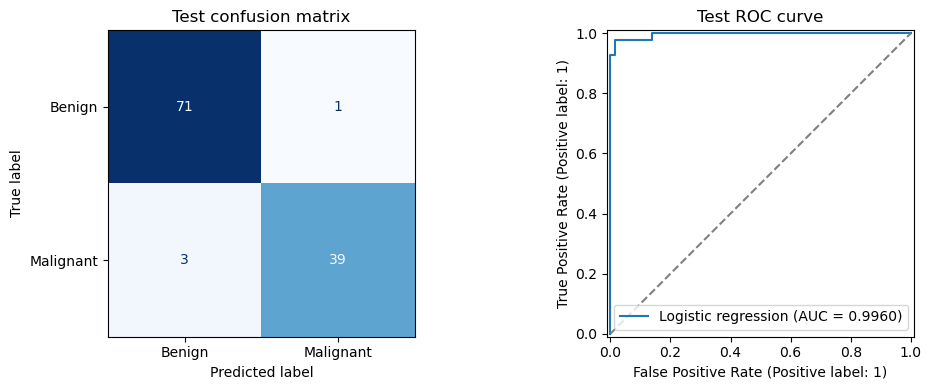

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred,
    display_labels=["Benign", "Malignant"],
    cmap="Blues",
    colorbar=False,
    ax=axes[0]
)
axes[0].set_title("Test confusion matrix")

RocCurveDisplay.from_predictions(y_test, y_score, ax=axes[1])
axes[1].plot([0, 1], [0, 1], "--", color="grey")
axes[1].set_title("Test ROC curve")
axes[1].legend([f"Logistic regression (AUC = {test_metrics['roc_auc']:.4f})"])

plt.tight_layout()
plt.show()

Logistic regression was selected because it achieved the highest mean validation ROC-AUC (0.9958). On the held-out test set, it achieved 96.5% accuracy, 97.5% precision, 92.9% recall and a ROC-AUC of 0.9960. It correctly classified 110 of 114 observations, missing three malignant cases and incorrectly classifying one benign case as malignant.

These results show that supervised learning can distinguish the two classes accurately in this dataset. PCA preserved similar validation performance with fewer dimensions, while feature selection reduced recall. However, the missed malignant cases highlight that high overall accuracy does not guarantee detection of every malignant case. The dataset is small, and further evaluation on independent data would be needed to assess how well the model generalizes.


Esta es 100% IA, no me da la cabeza ahora para escribirlo pero quería dejarlo acabado jajajaja